# RQ3 — Impact of NDCG weighting on behavior

Six-panel sweep figure.

- x-axis: NDCG coefficient (0.5, 1.0, 1.5, 2.0).
- The coefficient-2.0 condition is the base CQL policy (`cql_full_tree_traces_50_msmarco_dev.csv`).
- Panels show mean final NDCG@50, mean final Recall@50, mean cumulative abstract cost, mean cumulative latency, immediate STOP rate, and mean number of enhancement operations.

For each trace CSV we keep the last terminal row per `query_id` to obtain the final cumulative cost/latency and final effectiveness scores.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_DIR = Path("../relevant_csvs")

weight_files = {
    0.5: "cql_full_tree_50_msmarco_traces_alpha05.csv",
    1.0: "cql_full_tree_50_msmarco_traces_alpha10.csv",
    1.5: "cql_full_tree_50_msmarco_traces_alpha15.csv",
    2.0: "cql_full_tree_traces_50_msmarco_dev.csv",  # base CQL policy
}


def summarize_weight(weight, file_name):
    """Return per-coefficient summary metrics."""
    df = pd.read_csv(CSV_DIR / file_name)
    terminal = df[df["terminal"] == 1].sort_values("step").groupby("query_id").last()

    # Immediate STOP: first action of the trace is STOP.
    first_action = df.sort_values("step").groupby("query_id").first()
    immediate_stop = (first_action["action_name"] == "STOP").mean() * 100

    # Enhancement operations = every non-STOP action in the trace.
    enhancement_count = df[~df["action_name"].isin(["STOP"])].groupby("query_id").size()
    enhancement_count = enhancement_count.reindex(terminal.index, fill_value=0)

    return pd.Series({
        "weight": weight,
        "n_queries": terminal.shape[0],
        "NDCG": terminal["ndcg_after"].mean(),
        "Recall": terminal["recall_after"].mean(),
        "cost": terminal["cumulative_cost"].mean(),
        "latency_ms": terminal["cumulative_latency_ms"].mean(),
        "immediate_stop_pct": immediate_stop,
        "mean_enhancements": enhancement_count.mean(),
    })


rows = [summarize_weight(w, fn) for w, fn in weight_files.items()]
sweep_df = pd.DataFrame(rows).sort_values("weight")
sweep_df

,weight,n_queries,NDCG,Recall,cost,latency_ms,immediate_stop_pct,mean_enhancements
0,0.5,50.0,0.100597,0.140000,0.122000,557.334068,80.0,0.220000
1,1.0,50.0,0.100597,0.140000,0.200000,1097.448343,56.0,0.480000
2,1.5,48.0,0.089766,0.145833,0.247917,637.420642,44.0,0.583333
3,2.0,50.0,0.078178,0.140000,0.404000,822.665586,22.0,0.880000


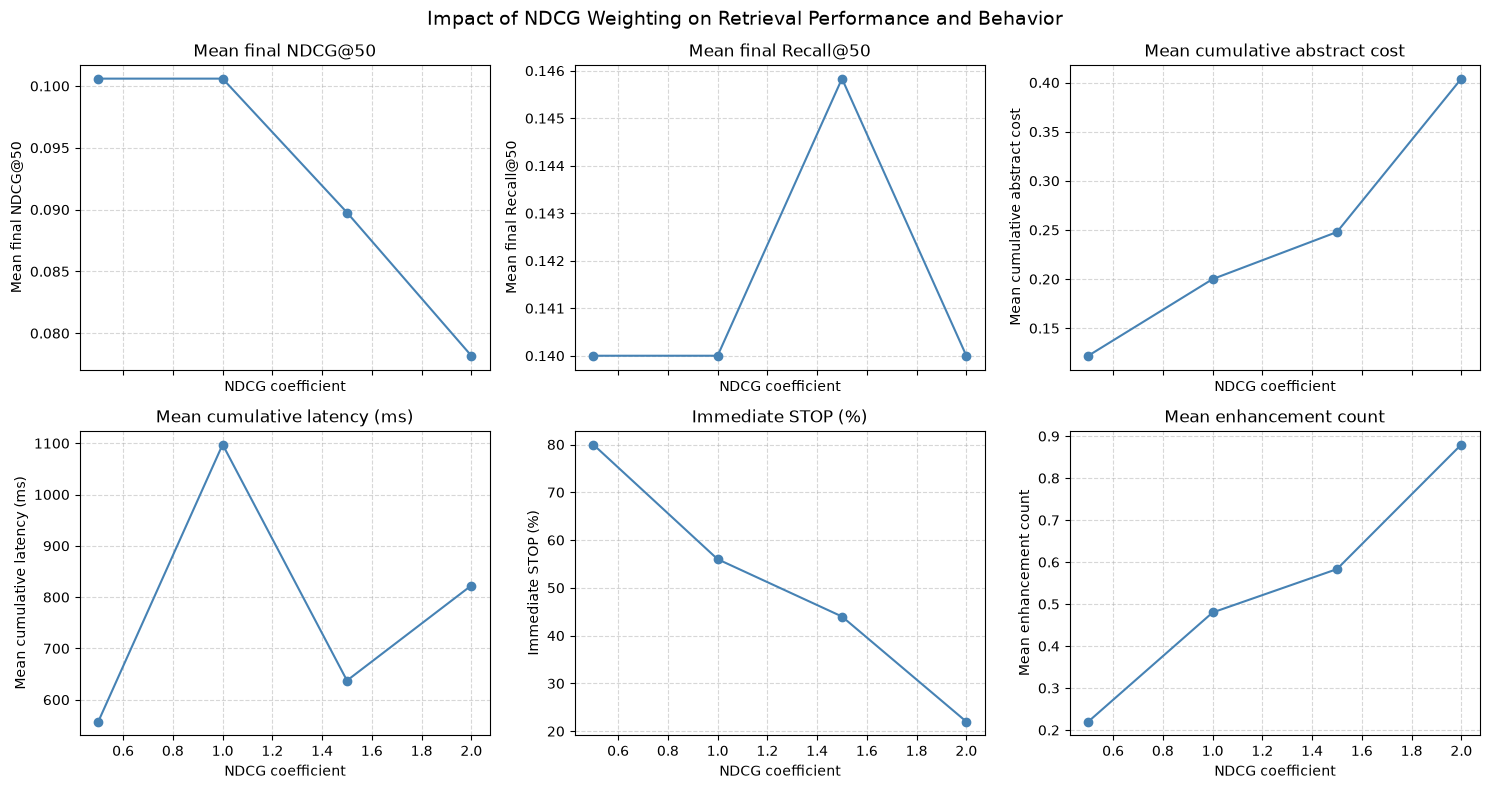

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.ravel()

panels = [
    ("NDCG", "Mean final NDCG@50"),
    ("Recall", "Mean final Recall@50"),
    ("cost", "Mean cumulative abstract cost"),
    ("latency_ms", "Mean cumulative latency (ms)"),
    ("immediate_stop_pct", "Immediate STOP (%)"),
    ("mean_enhancements", "Mean enhancement count"),
]

for ax, (col, title) in zip(axes, panels):
    ax.plot(sweep_df["weight"], sweep_df[col], marker="o", color="steelblue")
    ax.set_xlabel("NDCG coefficient")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Impact of NDCG Weighting on Retrieval Performance and Behavior", fontsize=14)
fig.tight_layout()
plt.show()